# What goes with happiness? A survey analysis of US adults, 2024

**Sample project built with public data.** Data: General Social Survey (GSS) 2024, NORC at the University of
Chicago. Analysis and report by Marlon Jiménez Valencia.

**Question.** Which personal circumstances are associated with saying you are "very happy"? We look at marital
status, self-rated health and satisfaction with one's financial situation, and then estimate all of them together,
with age, sex, education and religious attendance, in a logistic regression.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyreadstat
import statsmodels.api as sm
from IPython.display import Markdown, display
from sklearn.metrics import roc_auc_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT.parent / "common"))
import brand  # noqa: E402
import survey as sv  # noqa: E402

warnings.filterwarnings("ignore")
brand.apply_mpl_style()
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160})
FIG = ROOT / "output" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 1)


def md(text: str) -> None:
    display(Markdown(text))


def pct(x: float, d: int = 1) -> str:
    return f"{100 * x:.{d}f}%"

## 1. Data and method

* **Survey.** The GSS is a nationally representative, face-to-face and web survey of US adults run since 1972.
  The 2024 file has 3,986 respondents. Variable definitions come from the official GSS 2024 codebook
  (see `docs/variables.md`).
* **Weights and design.** All percentages use the weight `WTSSNRPS_AS`, which NORC recommends for analysing all
  2024 cases together (including the AmeriSpeak oversample). Confidence intervals and the regression standard
  errors take into account the stratified, clustered design (`VSTRAT`, `VPSU`), so they are wider than simple
  random-sample formulas would give.
* **Missing data.** "Don't know", "no answer" and "skipped" are treated as missing; each analysis uses the
  respondents with valid answers for its variables (complete cases).

In [2]:
RAW = ROOT / "data" / "raw" / "GSS2024.dta"
cols = ["happy", "marital", "health", "satfin", "age", "sex", "degree", "attend", "wtssnrps_as", "vstrat", "vpsu"]
raw, meta = pyreadstat.read_dta(str(RAW), usecols=cols, apply_value_formats=False)

d = pd.DataFrame({"w": raw["wtssnrps_as"], "strata": raw["vstrat"], "psu": raw["vstrat"] * 10 + raw["vpsu"]})
d["happiness"] = raw["happy"].map({1: "Very happy", 2: "Pretty happy", 3: "Not too happy"})
d["very_happy"] = raw["happy"].map({1: 1, 2: 0, 3: 0})
d["marital"] = raw["marital"].map({1: "Married", 2: "Widowed", 3: "Divorced / separated", 4: "Divorced / separated",
                                   5: "Never married"})
d["health"] = raw["health"].map({1: "Excellent", 2: "Good", 3: "Fair", 4: "Poor"})
d["finances"] = raw["satfin"].map({1: "Satisfied", 2: "More or less satisfied", 3: "Not satisfied at all"})
d["age"] = raw["age"]
d["age_group"] = pd.cut(raw["age"], [17, 34, 49, 64, 120], labels=["18-34", "35-49", "50-64", "65+"])
d["sex"] = raw["sex"].map({1: "Male", 2: "Female"})
d["college"] = raw["degree"].map(lambda x: np.nan if pd.isna(x) else ("Bachelor's or higher" if x >= 3
                                                                       else "No bachelor's degree"))
d["religious_monthly"] = raw["attend"].map(lambda x: np.nan if pd.isna(x) else ("Monthly or more" if x >= 4
                                                                               else "Less than monthly"))
ORDER = {"marital": ["Married", "Never married", "Divorced / separated", "Widowed"],
         "health": ["Excellent", "Good", "Fair", "Poor"],
         "finances": ["Satisfied", "More or less satisfied", "Not satisfied at all"],
         "happiness": ["Very happy", "Pretty happy", "Not too happy"]}
md(f"Respondents: **{len(d):,}** · valid answers to the happiness question: **{d['happiness'].notna().sum():,}** · "
   f"variance strata: {d['strata'].nunique()} · primary sampling units: {d['psu'].nunique()}.")

Respondents: **3,986** · valid answers to the happiness question: **3,954** · variance strata: 68 · primary sampling units: 137.

## 2. Who is in the sample

Weighted percentages describe the US adult population; *n* is the number of respondents (unweighted).

In [3]:
rows = []
for var, label in [("sex", "Sex"), ("age_group", "Age"), ("college", "Education"), ("marital", "Marital status"),
                   ("health", "Self-rated health"), ("finances", "Financial satisfaction"),
                   ("religious_monthly", "Religious attendance")]:
    sub = d[d[var].notna()]
    shares = sub.groupby(var, observed=True)["w"].sum() / sub["w"].sum()
    counts = sub.groupby(var, observed=True).size()
    order = ORDER.get(var, list(shares.index))
    for k in order:
        rows.append({"Variable": label, "Group": k, "Weighted %": 100 * shares[k], "n": int(counts[k])})
sample = pd.DataFrame(rows)
sample_display = sample.copy()
sample_display.loc[sample_display["Variable"].duplicated(), "Variable"] = ""
display(sample_display.style.hide(axis="index").format({"Weighted %": "{:.1f}", "n": "{:,}"}))

Variable,Group,Weighted %,n
Sex,Female,51.0,"2,169"
,Male,49.0,"1,787"
Age,18-34,30.9,"1,074"
,35-49,25.4,"1,057"
,50-64,22.3,857
,65+,21.5,871
Education,Bachelor's or higher,33.6,"1,440"
,No bachelor's degree,66.4,"2,539"
Marital status,Married,51.1,"1,659"
,Never married,30.4,"1,334"


## 3. How happy are Americans?

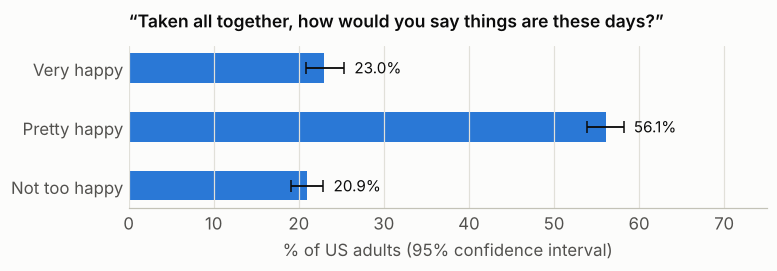

About **23.0%** of US adults say they are *very happy* (95% CI 20.8% to 25.3%); 56% say *pretty happy*. The design effect for this estimate is 2.8: the clustered sample makes the interval about 1.7 times as wide as a simple random sample of the same size would.

In [4]:
dist = []
for level in ORDER["happiness"]:
    r = sv.proportion((d["happiness"] == level).where(d["happiness"].notna()), d["w"], d["strata"], d["psu"])
    dist.append({"Answer": level, "Share": r["p"], "lo": r["lo"], "hi": r["hi"], "deff": r["deff"], "n": r["n"]})
dist = pd.DataFrame(dist)

fig, ax = plt.subplots(figsize=(7.2, 2.6))
ax.barh(dist["Answer"], 100 * dist["Share"], color=brand.BLUE, height=0.5)
ax.errorbar(100 * dist["Share"], dist["Answer"], xerr=[100 * (dist["Share"] - dist["lo"]),
            100 * (dist["hi"] - dist["Share"])], fmt="none", ecolor=brand.INK, capsize=4, lw=1.2)
for i, r in dist.iterrows():
    ax.text(100 * r["hi"] + 1.2, i, f"{100 * r['Share']:.1f}%", va="center", fontsize=10)
ax.invert_yaxis(); ax.set_xlim(0, 75); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("% of US adults (95% confidence interval)")
ax.set_title("“Taken all together, how would you say things are these days?”", fontsize=11.5)
fig.tight_layout(); fig.savefig(FIG / "happiness_distribution.png"); plt.show()
vh = dist.set_index("Answer").loc["Very happy"]
ph_ = dist.set_index("Answer").loc["Pretty happy", "Share"]
md(f"About **{pct(vh['Share'])}** of US adults say they are *very happy* (95% CI {pct(vh['lo'])} to "
   f"{pct(vh['hi'])}); {pct(ph_, 0)} say *pretty happy*. The design effect for this estimate is {vh['deff']:.1f}: the "
   "clustered sample makes the interval about "
   f"{np.sqrt(vh['deff']):.1f} times as wide as a simple random sample of the same size would.")

## 4. Cross-tabulations and chi-square tests

Each table shows **row percentages** (weighted): for example, of married adults, what share is very happy.
The **chi-square test** checks whether happiness and the other variable are independent (null hypothesis: no
association). It is computed on the respondent counts; all expected counts are well above 5, so the test is valid.
**Cramér's V** measures the strength of the association (0 = none, about 0.1 = small, 0.3 = medium).

In [5]:
tests = {}
for var, label in [("marital", "Marital status"), ("health", "Self-rated health"),
                   ("finances", "Financial satisfaction")]:
    sub = d[d["happiness"].notna() & d[var].notna()]
    tab = sv.weighted_crosstab(sub, var, "happiness", "w").loc[ORDER[var], ORDER["happiness"]]
    tab["n"] = sub.groupby(var).size().loc[ORDER[var]]
    t = sv.chi_square(sub, var, "happiness")
    tests[var] = t
    md(f"**Happiness by {label.lower()}** (row %, weighted)")
    display(tab.style.format({c: "{:.1f}" for c in ORDER["happiness"]} | {"n": "{:,}"}))
    md(f"χ²({t['dof']}) = {t['chi2']:.1f}, p {sv.fmt_p(t['p'])}, Cramér's V = {t['cramers_v']:.2f}, "
       f"n = {t['n']:,}, smallest expected count = {t['min_expected']:.0f}.")

**Happiness by marital status** (row %, weighted)

happiness,Very happy,Pretty happy,Not too happy,n
marital,,,,
Married,31.7,56.1,12.3,"1,647"
Never married,13.4,55.0,31.7,"1,325"
Divorced / separated,15.3,58.9,25.8,702
Widowed,15.1,53.7,31.2,266


χ²(6) = 211.5, p < 0.001, Cramér's V = 0.16, n = 3,940, smallest expected count = 54.

**Happiness by self-rated health** (row %, weighted)

happiness,Very happy,Pretty happy,Not too happy,n
health,,,,
Excellent,40.8,45.4,13.8,663
Good,23.3,59.6,17.1,"2,136"
Fair,10.2,59.6,30.2,972
Poor,14.7,35.0,50.3,171


χ²(6) = 338.9, p < 0.001, Cramér's V = 0.21, n = 3,942, smallest expected count = 34.

**Happiness by financial satisfaction** (row %, weighted)

happiness,Very happy,Pretty happy,Not too happy,n
finances,,,,
Satisfied,38.6,51.9,9.5,885
More or less satisfied,21.4,62.3,16.3,"1,799"
Not satisfied at all,13.9,50.2,35.9,"1,253"


χ²(4) = 396.2, p < 0.001, Cramér's V = 0.22, n = 3,937, smallest expected count = 178.

## 5. Share who are "very happy", with 95% confidence intervals

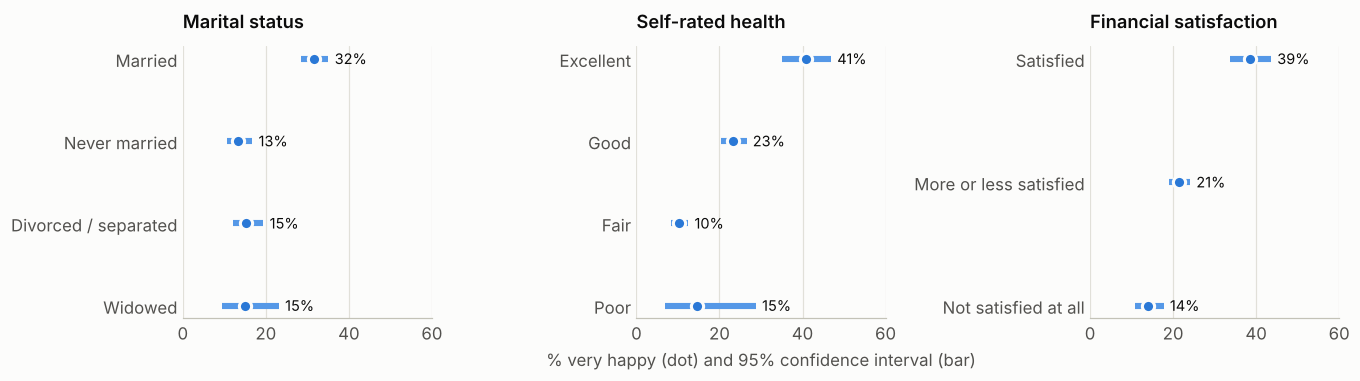

* **Marriage:** 32% of married adults are very happy, against 13% of those never married; the confidence intervals do not overlap.
* **Health:** 41% of people in excellent health are very happy, against 15% of those in poor health.
* **Money:** 39% of those satisfied with their finances are very happy, against 14% of those not satisfied at all.

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), sharex=True)
ci = {}
for ax, (var, title) in zip(axes, [("marital", "Marital status"), ("health", "Self-rated health"),
                                   ("finances", "Financial satisfaction")]):
    t = sv.proportions_by(d, "happiness", "Very happy", var, "w", "strata", "psu").set_index(var).loc[ORDER[var]]
    ci[var] = t
    y = np.arange(len(t))
    ax.hlines(y, 100 * t["lo"], 100 * t["hi"], color=brand.BLUE_RAMP[5], lw=4)
    ax.plot(100 * t["share"], y, "o", color=brand.BLUE, ms=8, mec=brand.SURFACE, mew=2)
    for i, (_, r) in enumerate(t.iterrows()):
        ax.text(100 * r["hi"] + 1.5, i, f"{100 * r['share']:.0f}%", va="center", fontsize=9.5)
    ax.set_yticks(y, t.index); ax.invert_yaxis(); ax.set_title(title, fontsize=12)
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True); ax.set_xlim(0, 60)
axes[1].set_xlabel("% very happy (dot) and 95% confidence interval (bar)")
fig.tight_layout(); fig.savefig(FIG / "very_happy_by_group.png"); plt.show()
m, h, f_ = ci["marital"], ci["health"], ci["finances"]
pd.concat({k: v.rename_axis("group") for k, v in ci.items()}, names=["variable"]).to_csv(
    ROOT / "output" / "very_happy_by_group.csv")
overlap = m.loc["Married", "lo"] <= m.loc["Never married", "hi"]
md(f"* **Marriage:** {pct(m.loc['Married', 'share'], 0)} of married adults are very happy, against "
   f"{pct(m.loc['Never married', 'share'], 0)} of those never married"
   f"{'.' if overlap else '; the confidence intervals do not overlap.'}\n"
   f"* **Health:** {pct(h.loc['Excellent', 'share'], 0)} of people in excellent health are very happy, against "
   f"{pct(h.loc['Poor', 'share'], 0)} of those in poor health.\n"
   f"* **Money:** {pct(f_.loc['Satisfied', 'share'], 0)} of those satisfied with their finances are very happy, "
   f"against {pct(f_.loc['Not satisfied at all', 'share'], 0)} of those not satisfied at all.")

## 6. Logistic regression: what predicts being "very happy", all else equal?

The cross-tabs look at one factor at a time. Married people are older on average, healthier people tend to have
more money, and so on, so the regression estimates the association of each factor **holding the others
constant**. Outcome: 1 = very happy, 0 = pretty or not too happy. Reference groups: married, excellent health,
satisfied with finances, age 18-34, male, no bachelor's degree, attends religious services less than monthly.

Estimation: weighted logistic regression (survey weight `WTSSNRPS_AS`) with standard errors clustered by primary
sampling unit, a standard approximation to design-based ("svy") logistic regression.

In [7]:
model_vars = ["very_happy", "marital", "health", "finances", "age_group", "sex", "college", "religious_monthly"]
md_ = d.dropna(subset=model_vars + ["w"]).copy()
X = pd.get_dummies(md_[model_vars[1:]].astype(str), drop_first=False, dtype=float)
drop = ["marital_Married", "health_Excellent", "finances_Satisfied", "age_group_18-34", "sex_Male",
        "college_No bachelor's degree", "religious_monthly_Less than monthly"]
X = sm.add_constant(X.drop(columns=drop))
y = md_["very_happy"].astype(float)
wn = md_["w"] / md_["w"].mean()
glm = sm.GLM(y, X, family=sm.families.Binomial(), var_weights=wn)
res = glm.fit(cov_type="cluster", cov_kwds={"groups": md_["psu"].astype(int)})
null = sm.GLM(y, X[["const"]], family=sm.families.Binomial(), var_weights=wn).fit()

pretty = {"marital_Never married": "Never married (vs married)", "marital_Divorced / separated":
          "Divorced / separated (vs married)", "marital_Widowed": "Widowed (vs married)",
          "health_Good": "Good health (vs excellent)", "health_Fair": "Fair health (vs excellent)",
          "health_Poor": "Poor health (vs excellent)",
          "finances_More or less satisfied": "Finances: more or less satisfied (vs satisfied)",
          "finances_Not satisfied at all": "Finances: not satisfied at all (vs satisfied)",
          "age_group_35-49": "Age 35-49 (vs 18-34)", "age_group_50-64": "Age 50-64 (vs 18-34)",
          "age_group_65+": "Age 65+ (vs 18-34)", "sex_Female": "Female (vs male)",
          "college_Bachelor's or higher": "Bachelor's degree or higher", "religious_monthly_Monthly or more":
          "Religious services monthly or more"}
ci_ = res.conf_int()
coef = pd.DataFrame({"Odds ratio": np.exp(res.params), "95% CI low": np.exp(ci_[0]), "95% CI high": np.exp(ci_[1]),
                     "p-value": res.pvalues}).drop(index="const")

# Average marginal effects (percentage points): change in predicted probability when the dummy goes 0 -> 1,
# averaged over the sample with the survey weights.
ame = {}
for c in coef.index:
    X1, X0 = X.copy(), X.copy()
    group = c.split("_")[0] + "_"
    same = [k for k in X.columns if k.startswith(group) and k != c] if not c.startswith(("sex", "college",
                                                                                          "religious")) else []
    X1[same] = 0; X0[same] = 0; X1[c] = 1; X0[c] = 0
    ame[c] = np.average(res.predict(X1) - res.predict(X0), weights=wn)
coef["Change in probability (pp)"] = pd.Series(ame) * 100
coef.index = [pretty[c] for c in coef.index]
display(coef.style.format({"Odds ratio": "{:.2f}", "95% CI low": "{:.2f}", "95% CI high": "{:.2f}",
                           "p-value": lambda p: sv.fmt_p(p), "Change in probability (pp)": "{:+.1f}"}))
mcfadden = 1 - res.llf / null.llf
auc = roc_auc_score(y, res.predict(X), sample_weight=wn)
md(f"n = {len(md_):,} respondents with complete data ({int(y.sum()):,} very happy). "
   f"McFadden pseudo-R² = {mcfadden:.3f}; area under the ROC curve = {auc:.2f}.")

,Odds ratio,95% CI low,95% CI high,p-value,Change in probability (pp)
Divorced / separated (vs married),0.46,0.33,0.64,< 0.001,-12.5
Never married (vs married),0.35,0.24,0.50,< 0.001,-16.0
Widowed (vs married),0.39,0.23,0.65,< 0.001,-14.8
Fair health (vs excellent),0.20,0.14,0.30,< 0.001,-25.5
Good health (vs excellent),0.46,0.34,0.62,< 0.001,-14.8
Poor health (vs excellent),0.28,0.12,0.63,0.002,-21.9
Finances: more or less satisfied (vs satisfied),0.53,0.40,0.69,< 0.001,-11.3
Finances: not satisfied at all (vs satisfied),0.38,0.27,0.53,< 0.001,-15.9
Age 35-49 (vs 18-34),0.94,0.66,1.32,0.709,-1.0
Age 50-64 (vs 18-34),0.73,0.52,1.04,0.080,-4.6


n = 3,760 respondents with complete data (752 very happy). McFadden pseudo-R² = 0.115; area under the ROC curve = 0.73.

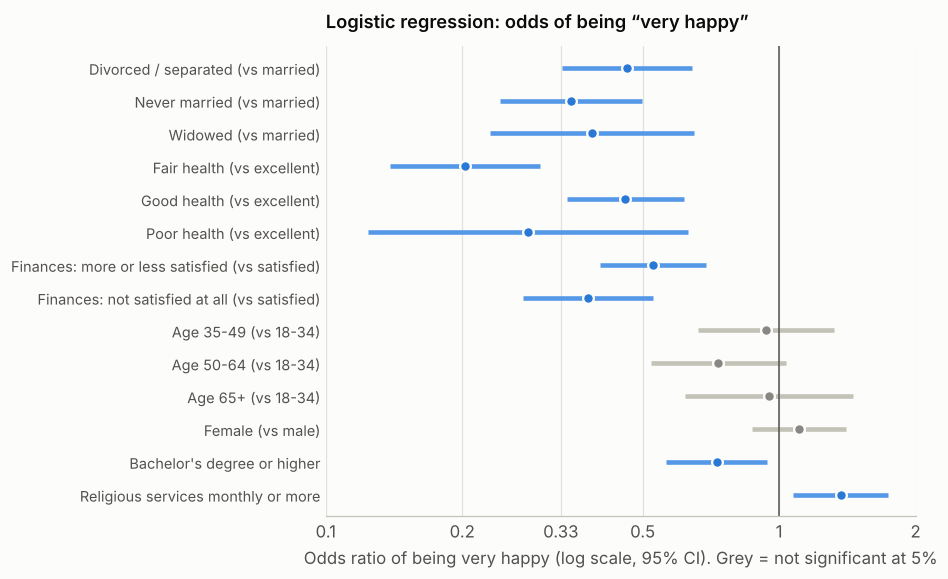

In [8]:
fig, ax = plt.subplots(figsize=(8.6, 5.4))
cf = coef.iloc[::-1]
yy = np.arange(len(cf))
sig = cf["p-value"] < 0.05
ax.hlines(yy, cf["95% CI low"], cf["95% CI high"], color=[brand.BLUE_RAMP[5] if s else brand.AXIS for s in sig], lw=3)
ax.plot(cf["Odds ratio"], yy, "o", color=brand.BLUE, ms=7, mec=brand.SURFACE, mew=1.5)
ax.plot(cf.loc[~sig, "Odds ratio"], yy[~sig.values], "o", color=brand.MUTED, ms=7, mec=brand.SURFACE, mew=1.5)
ax.axvline(1, color=brand.INK_2, lw=1)
ax.set_xscale("log"); ax.set_xticks([0.1, 0.2, 0.33, 0.5, 1, 2], ["0.1", "0.2", "0.33", "0.5", "1", "2"])
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_yticks(yy, cf.index, fontsize=9.5); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("Odds ratio of being very happy (log scale, 95% CI). Grey = not significant at 5%")
ax.set_title("Logistic regression: odds of being “very happy”", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "odds_ratios.png"); plt.show()

### Checking the model's assumptions

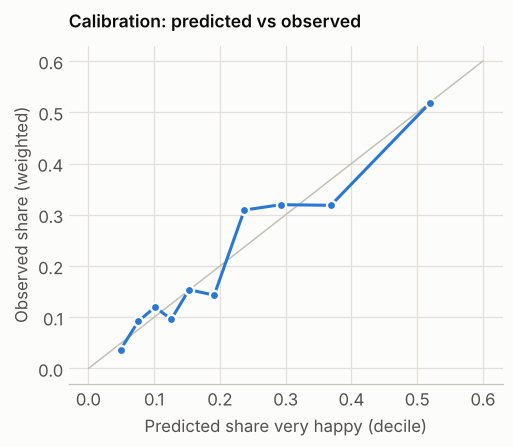

* **Independent observations.** Respondents are clustered by sampling unit; this is handled by the clustered standard errors (137 clusters).
* **Enough events.** 54 events per predictor (rule of thumb: at least 10).
* **No harmful multicollinearity.** Highest variance inflation factor = 2.02 (problems usually start above 5).
* **Linearity of the logit in age.** Age enters as four groups, so no straight-line assumption is made.
* **Influential observations.** Largest Cook's distance = 0.0076, about 7 times the common warning level of 4/n = 0.0011; 270 cases exceed that level, but all distances are far below 1, so no single respondent drives the results.
* **Fit.** Across deciles of predicted probability, observed and predicted shares differ by at most 7.2 percentage points (plot). The Hosmer-Lemeshow test on the unweighted fit gives χ²(8) = 16.9, p = 0.03: it flags some lack of fit. With almost 4,000 respondents the test detects even modest deviations, so read it together with the plot: the model ranks respondents reasonably well (AUC 0.73), but its predicted probabilities can be off by a few points in some groups and should be read as approximate. Pseudo-R² 0.115 is typical for attitudes: happiness depends on much more than these variables.

In [9]:
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=X.columns[1:])
unw = sm.GLM(y, X, family=sm.families.Binomial()).fit()
infl = unw.get_influence()
cooks = infl.cooks_distance[0]
md_["p_hat"] = res.predict(X)
md_["decile"] = pd.qcut(md_["p_hat"], 10, labels=False, duplicates="drop")
cal = md_.groupby("decile").apply(lambda g: pd.Series({"predicted": np.average(g["p_hat"], weights=g["w"]),
                                                       "observed": np.average(g["very_happy"], weights=g["w"]),
                                                       "n": len(g)}))
# Hosmer-Lemeshow on the unweighted fit (10 groups)
from scipy import stats as _st  # noqa: E402
ph = unw.predict(X)
grp = pd.qcut(ph, 10, labels=False, duplicates="drop")
obs = y.groupby(grp).sum(); exp_ = ph.groupby(grp).sum(); nn = y.groupby(grp).size()
hl = (((obs - exp_) ** 2) / (exp_ * (1 - exp_ / nn))).sum()
hl_p = 1 - _st.chi2.cdf(hl, len(obs) - 2)
cal_gap = (cal["observed"] - cal["predicted"]).abs().max()
epv = min(y.sum(), len(y) - y.sum()) / (X.shape[1] - 1)

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.plot([0, 0.6], [0, 0.6], color=brand.AXIS, lw=1)
ax.plot(cal["predicted"], cal["observed"], "o-", color=brand.BLUE, ms=6, mec=brand.SURFACE, mew=1.5)
ax.set_xlabel("Predicted share very happy (decile)"); ax.set_ylabel("Observed share (weighted)")
ax.set_title("Calibration: predicted vs observed", fontsize=11.5); ax.grid(True)
fig.tight_layout(); fig.savefig(FIG / "calibration.png"); plt.show()

md(f"* **Independent observations.** Respondents are clustered by sampling unit; this is handled by the clustered "
   f"standard errors ({md_['psu'].nunique()} clusters).\n"
   f"* **Enough events.** {epv:.0f} events per predictor (rule of thumb: at least 10).\n"
   f"* **No harmful multicollinearity.** Highest variance inflation factor = {vif.max():.2f} "
   f"(problems usually start above 5).\n"
   f"* **Linearity of the logit in age.** Age enters as four groups, so no straight-line assumption is made.\n"
   f"* **Influential observations.** Largest Cook's distance = {cooks.max():.4f}, about "
   f"{cooks.max() / (4 / len(y)):.0f} times the common warning level of 4/n = {4 / len(y):.4f}; "
   f"{int((cooks > 4 / len(y)).sum())} cases exceed that level, but all distances are far below 1, so no single "
   f"respondent drives the results.\n"
   f"* **Fit.** Across deciles of predicted probability, observed and predicted shares differ by at most "
   f"{100 * cal_gap:.1f} percentage points (plot). The Hosmer-Lemeshow test on the unweighted fit gives "
   f"χ²({len(obs) - 2}) = {hl:.1f}, p = {hl_p:.2f}"
   + (" (no evidence of poor fit)." if hl_p >= 0.05 else
      ": it flags some lack of fit. With almost 4,000 respondents the test detects even modest deviations, so read "
      "it together with the plot: the model ranks respondents reasonably well (AUC "
      f"{auc:.2f}), but its predicted probabilities can be off by a few points in some groups and should be read "
      "as approximate.")
   + f" Pseudo-R² {mcfadden:.3f} is typical for attitudes: happiness depends on much more than these variables.")

## 7. What this means, in plain language

In [10]:
c = coef
def ame_of(k):
    return c.loc[k, "Change in probability (pp)"]
md(f"""
* **Marriage matters even after accounting for health, money and age.** Compared with otherwise similar married
  people, the never-married are about **{abs(ame_of('Never married (vs married)')):.0f} percentage points** less
  likely to say they are very happy (odds ratio {c.loc['Never married (vs married)', 'Odds ratio']:.2f}); the
  divorced or separated about **{abs(ame_of('Divorced / separated (vs married)')):.0f} points** less.
* **Health shows the largest gaps.** Compared with people in excellent health, those in fair health are about
  **{abs(ame_of('Fair health (vs excellent)')):.0f} points** less likely to be very happy and those in poor health
  about **{abs(ame_of('Poor health (vs excellent)')):.0f} points** less (odds ratios
  {c.loc['Fair health (vs excellent)', 'Odds ratio']:.2f} and {c.loc['Poor health (vs excellent)', 'Odds ratio']:.2f};
  the poor-health group is small, so its estimate is less precise).
* **Feeling financially secure matters too.** Those not satisfied at all with their finances are about
  **{abs(ame_of('Finances: not satisfied at all (vs satisfied)')):.0f} points** less likely to be very happy than
  those who are satisfied.
* **Smaller associations.** Attending religious services at least monthly goes with a
  {ame_of('Religious services monthly or more'):+.0f}-point difference
  (p = {sv.fmt_p(c.loc['Religious services monthly or more', 'p-value'])}). Once health and financial satisfaction
  are held constant, a bachelor's degree goes with a {ame_of("Bachelor's degree or higher"):+.0f}-point difference
  (p = {sv.fmt_p(c.loc["Bachelor's degree or higher", 'p-value'])}): education seems to matter mainly through the
  other factors. Sex (p = {sv.fmt_p(c.loc['Female (vs male)', 'p-value'])}) and age group (all p ≥
  {min(c.loc[[k for k in c.index if k.startswith('Age')], 'p-value']):.2f}) show no clear difference.
* These are **associations, not causes**: happier people may also be more likely to marry or to rate their health
  as good.
""")


* **Marriage matters even after accounting for health, money and age.** Compared with otherwise similar married
  people, the never-married are about **16 percentage points** less
  likely to say they are very happy (odds ratio 0.35); the
  divorced or separated about **13 points** less.
* **Health shows the largest gaps.** Compared with people in excellent health, those in fair health are about
  **26 points** less likely to be very happy and those in poor health
  about **22 points** less (odds ratios
  0.20 and 0.28;
  the poor-health group is small, so its estimate is less precise).
* **Feeling financially secure matters too.** Those not satisfied at all with their finances are about
  **16 points** less likely to be very happy than
  those who are satisfied.
* **Smaller associations.** Attending religious services at least monthly goes with a
  +5-point difference
  (p = 0.011). Once health and financial satisfaction
  are held constant, a bachelor's degree goes with a -5-point difference
  (p = 0.015): education seems to matter mainly through the
  other factors. Sex (p = 0.406) and age group (all p ≥
  0.08) show no clear difference.
* These are **associations, not causes**: happier people may also be more likely to marry or to rate their health
  as good.


## 8. Limitations

* **Cross-sectional data:** one point in time, so the direction of the relationships cannot be established.
* **Self-reported answers:** happiness, health and financial satisfaction are the respondent's own assessment.
* **Mode of interview:** in 2024 most respondents answered on the web and the rest face-to-face or by phone;
  answers to sensitive questions can differ by mode.
* **Complete-case analysis:** respondents with a missing answer in any model variable are left out of the
  regression; results could change slightly with imputation.
* **Design approximation:** the regression uses weights plus cluster-robust errors, a close approximation to
  full design-based estimation; the cross-tab chi-square tests use respondent counts.

**Source.** Davern, M., Bautista, R., Freese, J., Herd, P. and Morgan, S. L. *General Social Survey 1972-2024*
[machine-readable data file], 2024 Release 3a. NORC at the University of Chicago, with principal funding from the
National Science Foundation. Data downloaded from gss.norc.org; used under the GSS terms (free use with citation).

In [11]:
results = {
    "n_total": int(len(d)), "n_happy_valid": int(d["happiness"].notna().sum()),
    "very_happy": {"p": float(vh["Share"]), "lo": float(vh["lo"]), "hi": float(vh["hi"])},
    "very_happy_married": float(m.loc["Married", "share"]), "very_happy_never_married": float(m.loc["Never married", "share"]),
    "very_happy_excellent_health": float(h.loc["Excellent", "share"]), "very_happy_poor_health": float(h.loc["Poor", "share"]),
    "very_happy_fin_satisfied": float(f_.loc["Satisfied", "share"]),
    "very_happy_fin_not": float(f_.loc["Not satisfied at all", "share"]),
    "chi2": {k: {"chi2": float(v["chi2"]), "dof": int(v["dof"]), "p": float(v["p"]), "v": float(v["cramers_v"])}
             for k, v in tests.items()},
    "model_n": int(len(md_)), "mcfadden": float(mcfadden), "auc": float(auc), "max_vif": float(vif.max()),
    "hl_p": float(hl_p), "cal_gap": float(cal_gap),
    "or": {k: float(v) for k, v in c["Odds ratio"].items()},
    "or_p": {k: float(v) for k, v in c["p-value"].items()},
    "ame_pp": {k: float(v) for k, v in c["Change in probability (pp)"].items()},
}
_ = (ROOT / "output" / "results.json").write_text(json.dumps(results, indent=2))